# Econ 524 — Lab: Identification of Causal Effects
## Part C — Difference-in-Differences: from the 2×2 to staggered adoption and high-dimensional controls

| Session | Date | Slides | Content |
|---|---|---|---|
| Part A | Fri 16 Oct | 5–11 | Potential outcomes, unconfoundedness, matching *(previous notebook)* |
| Part B | Fri 23 Oct | 13–28 | IV and LATE *(previous notebook)* |
| **Part C** | **Fri 30 Oct** | **29–46** | 2×2 DiD, no anticipation, parallel trends, staggered adoption, GT-ATTs (Callaway & Sant'Anna), conditional parallel trends with ML nuisances |

**Same design principle as Parts A and B.** We simulate *every* potential outcome, so the true
parameter is always known, and each estimator only sees what a real panel would contain. In DiD
exactly one column is missing from real data: $Y_1(0)$ for the treated, the outcome a treated unit
*would have had* after the policy date had it not been treated. Every estimator today is a
different way of imputing that one column.

**Notation follows the slides.** $D_t$ treatment at time $t$, $Y_t(d)$ potential outcomes,
$\theta_{ATT}$ the target in the 2×2; $G$ the first treated period, $Y_t(g)$ potential outcome
paths, $\theta_0(g,t)$ the group-time ATT, $\mathcal C_{gt}$ the comparison set, and $Z$ the
covariates. *Heads-up:* the slides index the 2×2 periods as $t\in\{0,1\}$ but the multi-period
case as $t = 1,\dots,T$ with $G \ge 2$. The 2×2 is the case $T = 2$, $G\in\{2,\infty\}$.

**Original sources behind the ideas**
- An early before/after, treated/untreated comparison: Snow (1855) on cholera and London's water
  companies (often credited as the first DiD-type design).
- The 2×2 we mimic: Card & Krueger (1994, *AER*).
- Pre-program dips and why "no anticipation" matters: Ashenfelter (1978, *REStat*); Ashenfelter &
  Card (1985, *REStat*).
- Conditional parallel trends: Heckman, Ichimura & Todd (1997, *REStud*); Abadie (2005, *REStud*).
- Group-time ATTs, comparison groups, aggregation: Callaway & Sant'Anna (2021, *J. Econometrics*).
- Why TWFE breaks with staggered timing: Goodman-Bacon (2021); de Chaisemartin & D'Haultfœuille
  (2020, *AER*); Sun & Abraham (2021); Borusyak, Jaravel & Spiess (2024, *REStud*).
- Doubly robust DiD: Sant'Anna & Zhao (2020, *J. Econometrics*), built on Robins, Rotnitzky &
  Zhao (1994, *JASA*); DML for DiD: Chang (2020, *Econometrics Journal*); the general recipe:
  Chernozhukov et al. (2018, *Econometrics Journal*).
- Practitioner's view of all of the above: Baker, Callaway, Cunningham, Goodman-Bacon & Sant'Anna
  (2026, *JEL*); CausalML book §16.2–16.3.

### Plan for the 50 minutes

| Block | Slides | Min |
|---|---|---|
| 0 Warm-up: New Jersey, 1992 | 30–33 | 3 |
| 1 The 2×2 setup and two naive comparisons | 30, 34 | 7 |
| 2 Identification: no anticipation, parallel trends, Theorem 3.1 | 35–40 | 9 |
| 3 When the assumptions fail | 36–37 | 4 |
| 4 Staggered adoption: GT-ATTs, comparison groups, event study | 41–43 | 12 |
| 5 Conditional parallel trends with high-dimensional $Z$ | 44–46 | 13 |
| Wrap-up | — | 2 |
| *Take-home* | — | — |

**By the end of Part C you should be able to:**
1. Write the slide-34 decomposition and say which unobservable term parallel trends replaces with
   an observable one.
2. Compute the 2×2 DiD four ways (two orderings of means, the interaction regression, first
   differences) and explain why they are the same number.
3. Show numerically that violations of no anticipation or parallel trends are **bias**, not noise.
4. Compute $\theta_0(g,t)$ by hand with never-treated and not-yet-treated comparisons, and
   aggregate them into an event study with the slide-42 weights.
5. Explain why conditional parallel trends turns DiD into a **high-dimensional nuisance**
   problem, and why plugging in a LASSO fit is not enough for valid inference.

In [1]:
import inspect
import warnings

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import (Lasso, LassoCV, LinearRegression,
                                  LogisticRegression, LogisticRegressionCV)
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore", category=FutureWarning)      # scikit-learn API churn
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# One fixed color order, used the same way in every figure
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.figsize": (7.5, 4), "figure.dpi": 110,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK2,
})

# L1-penalized logit. scikit-learn 1.8 renamed the argument (penalty="l1" -> l1_ratio=1),
# so we build the keyword once and the same call works on old and new versions.
_lr, _lrcv = (inspect.signature(c).parameters for c in (LogisticRegression, LogisticRegressionCV))
L1 = {"l1_ratio": 1.0} if _lr["penalty"].default == "deprecated" else {"penalty": "l1"}
L1CV = {"l1_ratios": (1.0,)} if _lrcv["penalty"].default == "deprecated" else {"penalty": "l1"}
if "use_legacy_attributes" in _lrcv:
    L1CV["use_legacy_attributes"] = False

---
## 0 Warm-up: New Jersey, 1992 (3 min, no code)

On **1 April 1992**, New Jersey raised its minimum wage from \$4.25 to \$5.05. Pennsylvania, next
door, did not. Card & Krueger surveyed about 410 fast-food restaurants on both sides of the border
in **Feb–Mar 1992** (before) and again in **Nov–Dec 1992** (after). The outcome is full-time
equivalent (FTE) employees per store (slide 33).

Their raw numbers (CK 1994, Table 3): NJ stores went from **20.44** to **21.03** FTE; PA stores
went from **23.33** to **21.17**.

Discuss with your neighbour:
1. The textbook prediction is lower employment in NJ. NJ employment *rose* by 0.59. Is $+0.59$ the
   effect of the minimum wage? What else happened to the region's labour market in 1992?
2. After the increase, NJ stores had 0.14 *fewer* FTE than PA stores. Is $-0.14$ the effect?
3. Each comparison fails for a different reason. What would you have to believe to combine them
   into one number that works?

Question 3 is the parallel-trends assumption (slide 37). The number you get is $0.59 - (-2.16) = 2.75$.

---
## 1 The 2×2 setup and two naive comparisons (slides 30, 34)

Two periods, two groups. Nobody is treated at $t = 0$ ($D_0 = 0$); New Jersey stores are treated
at $t = 1$ ($D_1 = 1$). Observed outcomes follow the switching equation (slide 30):

$$Y_t = D_t\,Y_t(1) + (1 - D_t)\,Y_t(0).$$

The parameter is the effect on the treated stores **after** the policy (slide 34):
$\theta_{ATT} = E[Y_1(1) - Y_1(0) \mid D_1 = 1]$. The term $E[Y_1(0) \mid D_1 = 1]$ is what we
never see.

### The data-generating process

We simulate $n = 4{,}100$ stores (ten times CK's survey, so sampling noise does not distract us),
calibrated to the CK means:

| | PA ($D_1 = 0$) | NJ ($D_1 = 1$) |
|---|---|---|
| share of stores | 0.19 | 0.81 |
| mean store size $E[Y_0(0)]$ (FTE) | 23.3 | 20.4 |
| untreated trend $E[Y_1(0) - Y_0(0)]$ | $-2.2$ | $-2.2$ *(parallel by construction)* |
| effect $Y_1(1) - Y_1(0)$ | — | mean 2.75, heterogeneous (sd 1.5) |

NJ stores are smaller to begin with, so the groups are **not** comparable in levels. They are
comparable in **trends**. Two knobs, used in Section 3, break the assumptions on purpose: `delta`
adds an extra untreated trend for NJ, and `antic` lets NJ stores react before the survey.

*This is a simulation calibrated to CK's means. It is not their data and it says nothing about the
real-world effect of minimum wages.*

In [2]:
rng = np.random.default_rng(19920401)

def simulate_ck(n=4_100, share_nj=0.81, trend=-2.2, att=2.75, delta=0.0, antic=0.0, rng=rng):
    '''Card-Krueger-style 2x2 with God's-eye potential outcomes (FTE employees per store).
    delta : extra untreated trend for NJ stores    -> breaks parallel trends (Section 3)
    antic : NJ response already present at t = 0  -> breaks no anticipation (Section 3)'''
    nj    = rng.binomial(1, share_nj, n)                           # D_1 = 1: store is in New Jersey
    alpha = np.where(nj == 1, 20.4, 23.3) + rng.normal(0, 7, n)    # store size: NJ stores smaller
    y_pre0  = alpha + rng.normal(0, 3, n)                          # Y_0(0)
    y_post0 = alpha + trend + delta * nj + rng.normal(0, 3, n)     # Y_1(0)
    y_post1 = y_post0 + att + rng.normal(0, 1.5, n)                # Y_1(1): effects vary by store
    y_pre   = y_pre0 + antic * nj                                  # observed Y_0  (= Y_0(0) under NA)
    y_post  = np.where(nj == 1, y_post1, y_post0)                  # observed Y_1  (switching equation)
    return pd.DataFrame({"store": np.arange(n), "nj": nj, "y_pre": y_pre, "y_post": y_post,
                         "y_pre0": y_pre0, "y_post0": y_post0, "y_post1": y_post1})

ck = simulate_ck()
ck.head(6)

,store,nj,y_pre,y_post,y_pre0,y_post0,y_post1
0,0,1,14.381,20.153,14.381,13.875,20.153
1,1,1,16.748,19.793,16.748,14.597,19.793
2,2,1,20.825,21.292,20.825,17.889,21.292
3,3,1,8.482,11.004,8.482,9.605,11.004
4,4,1,11.500,16.374,11.500,12.727,16.374
5,5,1,17.991,17.102,17.991,17.075,17.102


Column key: `y_pre0` $= Y_0(0)$, `y_post0` $= Y_1(0)$, `y_post1` $= Y_1(1)$ (God's eye), and
`y_pre` $= Y_0$, `y_post` $= Y_1$ (what a survey records). Here is what a real dataset would let
us see. The one hole that matters is $Y_1(0)$ for New Jersey:

In [3]:
seen = ck[["nj", "y_pre", "y_post"]].copy()
seen["Y_1(0) (seen?)"] = np.where(ck.nj == 0, ck.y_post0, np.nan)   # only PA stores reveal it
seen["Y_1(1) (seen?)"] = np.where(ck.nj == 1, ck.y_post1, np.nan)
seen.head(6)

,nj,y_pre,y_post,Y_1(0) (seen?),Y_1(1) (seen?)
0,1,14.381,20.153,NaN,20.153
1,1,16.748,19.793,NaN,19.793
2,1,20.825,21.292,NaN,21.292
3,1,8.482,11.004,NaN,11.004
4,1,11.500,16.374,NaN,16.374
5,1,17.991,17.102,NaN,17.102


### Exercise 1 (5 min)

Using the God's-eye `ck`:
1. Compute $\theta_{ATT}$.
2. Compute the **cross-section** comparison after the policy, $E[Y_1 \mid D_1=1] - E[Y_1 \mid D_1=0]$,
   and the **selection bias at $t=1$**, $E[Y_1(0) \mid D_1=1] - E[Y_1(0) \mid D_1=0]$. Check the
   slide-34 identity: cross-section $= \theta_{ATT} +$ selection bias.
3. Compute the **before–after** comparison in NJ, $E[Y_1 - Y_0 \mid D_1 = 1]$, and NJ's untreated
   trend $E[Y_1(0) - Y_0(0) \mid D_1 = 1]$. Check: before–after $= \theta_{ATT} +$ trend.
4. Compute the selection bias at $t = 0$, $E[Y_0(0) \mid D_1=1] - E[Y_0(0) \mid D_1=0]$. Compare it
   with the one at $t = 1$.

**Predict first:** which of the two naive comparisons is further from 2.75?

In [4]:
# ---- EXERCISE 1 -------------------------------------------------------------
T, C = ck.nj == 1, ck.nj == 0
ATT = (ck.y_post1 - ck.y_post0)[T].mean()

cross_section = ck.y_post[T].mean() - ck.y_post[C].mean()        # NJ vs PA, after
sel_bias_1    = ck.y_post0[T].mean() - ck.y_post0[C].mean()      # needs Y_1(0) for NJ: unobservable
before_after  = ck.y_post[T].mean() - ck.y_pre[T].mean()         # NJ after vs NJ before
nj_trend      = ck.y_post0[T].mean() - ck.y_pre0[T].mean()       # NJ's untreated trend: unobservable
sel_bias_0    = ck.y_pre0[T].mean() - ck.y_pre0[C].mean()        # observable (Y_0 = Y_0(0) under NA)

pd.Series({
    "ATT (true)": ATT,
    "cross-section (t=1)": cross_section,
    "  ATT + selection bias at t=1": ATT + sel_bias_1,
    "before-after (NJ)": before_after,
    "  ATT + NJ untreated trend": ATT + nj_trend,
    "selection bias at t=1 (unobservable)": sel_bias_1,
    "selection bias at t=0 (observable)": sel_bias_0,
})
# -----------------------------------------------------------------------------

ATT (true)                              2.785
cross-section (t=1)                    -0.150
  ATT + selection bias at t=1          -0.150
before-after (NJ)                       0.587
  ATT + NJ untreated trend              0.587
selection bias at t=1 (unobservable)   -2.935
selection bias at t=0 (observable)     -3.117
dtype: float64

**Reading the numbers.** Both naive comparisons are badly off, for different reasons:

- The **cross-section** (about $-0.15$) is contaminated by **selection bias**: NJ stores are about
  3 FTE smaller than PA stores, treatment or not. This is Part A's problem again.
- The **before–after** (about $+0.6$) is contaminated by **time**: employment fell about 2.2 FTE
  for reasons unrelated to the minimum wage.

The last two rows are the key to the whole lecture (slide 34, point 4). There are *two* "mean
differences in the absence of treatment", and they are about the same number. The one at $t = 1$
is the one we need and can never see. The one at $t = 0$ we can compute from the data. Parallel trends
is the assumption that lets us use the second in place of the first. In the population they are
equal; in this sample they differ by about 0.2, and that gap will be exactly the estimation error
of DiD in Exercise 2.

---
## 2 Identification: no anticipation, parallel trends, Theorem 3.1 (slides 35–40)

**Assumption 3.1 (No anticipation).** $Y_0 = Y_0(0)$ for every unit, including treated ones.
Treatment has no effect before it starts.

**Assumption 3.2 (Parallel trends).** (i) $D_0 = 0$ and $P(D_1 = 1) \in (0,1)$; (ii)
$$E[Y_1(0) \mid D_1 = 1] - E[Y_1(0) \mid D_1 = 0] = E[Y_0(0) \mid D_1 = 1] - E[Y_0(0) \mid D_1 = 0],$$
equivalently $E[Y_1(0) - Y_0(0) \mid D_1 = 1] = E[Y_1(0) - Y_0(0) \mid D_1 = 0]$: same untreated
*trend* in both groups. Levels may differ; selection bias at $t = 1$ may be nonzero (slide 37,
comment 4). It just has to equal the one at $t = 0$.

**Theorem 3.1, in three lines.** Each line uses exactly one ingredient:

$$
\begin{aligned}
E[Y_1 \mid D_1{=}1] - E[Y_1 \mid D_1{=}0]
&= \theta_{ATT} + \big\{E[Y_1(0) \mid D_1{=}1] - E[Y_1(0) \mid D_1{=}0]\big\} && \text{(switching eq., slide 34)}\\
&= \theta_{ATT} + \big\{E[Y_0(0) \mid D_1{=}1] - E[Y_0(0) \mid D_1{=}0]\big\} && \text{(PT, 3.2)}\\
&= \theta_{ATT} + \big\{E[Y_0 \mid D_1{=}1] - E[Y_0 \mid D_1{=}0]\big\} && \text{(NA, 3.1)}
\end{aligned}
$$

Move the last brace to the left and you have $\theta_{ATT} = \Delta_1 - \Delta_0$ (slide 39).
Regrouping the same four means gives the "time then groups" version (slide 40):
$\theta_{ATT} = E[Y_1 - Y_0 \mid D_1 = 1] - E[Y_1 - Y_0 \mid D_1 = 0]$.

### Exercise 2 (6 min)

1. Compute the four sample means. Compute DiD both ways: groups then time ($\Delta_1 - \Delta_0$)
   and time then groups.
2. Run the regression people actually run (slide 38, "just run a TWFE regression") on the
   *long* data: $Y_{it} = \beta_0 + \beta_1 D_i + \beta_2\, \text{Post}_t + \beta_3\, D_i \text{Post}_t + \varepsilon_{it}$,
   with standard errors clustered by store. Also regress the first difference $\Delta Y_i$ on $D_i$.
3. Map each $\hat\beta$ to one of the four means.

In [5]:
# ---- EXERCISE 2.1 -----------------------------------------------------------
means = (ck.groupby("nj")[["y_pre", "y_post"]].mean()
           .rename(index={0: "PA (D1=0)", 1: "NJ (D1=1)"}))
means["change"] = means.y_post - means.y_pre
display(means)

NJ, PA = means.loc["NJ (D1=1)"], means.loc["PA (D1=0)"]
groups_then_time = (NJ.y_post - PA.y_post) - (NJ.y_pre - PA.y_pre)     # Delta_1 - Delta_0
time_then_groups = NJ.change - PA.change
pd.Series({"ATT (true)": ATT, "DiD: groups then time": groups_then_time,
           "DiD: time then groups": time_then_groups})
# -----------------------------------------------------------------------------

,y_pre,y_post,change
nj,,,
PA (D1=0),23.618,21.237,-2.380
NJ (D1=1),20.501,21.088,0.587


ATT (true)              2.785
DiD: groups then time   2.967
DiD: time then groups   2.967
dtype: float64

In [6]:
# ---- EXERCISE 2.2-2.3 -------------------------------------------------------
long = ck.melt(id_vars=["store", "nj"], value_vars=["y_pre", "y_post"],
               var_name="period", value_name="y")
long["post"] = (long.period == "y_post").astype(int)
fit_int = smf.ols("y ~ nj + post + nj:post", data=long).fit(
    cov_type="cluster", cov_kwds={"groups": long.store})

ck["dy"] = ck.y_post - ck.y_pre
fit_fd = smf.ols("dy ~ nj", data=ck).fit(cov_type="HC1")

display(pd.DataFrame({
    "coefficient": fit_int.params,
    "equals": ["PA pre mean", "NJ pre - PA pre  (Delta_0)", "PA change", "DiD"],
    "check": [PA.y_pre, NJ.y_pre - PA.y_pre, PA.change, groups_then_time],
}))
pd.DataFrame({"estimate": [fit_int.params["nj:post"], fit_fd.params["nj"]],
              "SE": [fit_int.bse["nj:post"], fit_fd.bse["nj"]]},
             index=["interaction regression, clustered by store", "first differences, HC1"])
# -----------------------------------------------------------------------------

,coefficient,equals,check
Intercept,23.618,PA pre mean,23.618
nj,-3.117,NJ pre - PA pre (Delta_0),-3.117
post,-2.380,PA change,-2.380
nj:post,2.967,DiD,2.967


,estimate,SE
"interaction regression, clustered by store",2.967,0.163
"first differences, HC1",2.967,0.163


**All of these are the same number, exactly, not approximately.** The interaction regression is
*saturated* in (group, period), so its four fitted values are the four cell means and $\hat\beta_3$
is $\Delta_1 - \Delta_0$ by algebra. With two periods, a regression with store and period fixed
effects is the first-difference regression, which is the "time then groups" formula. The
standard errors agree up to a small-sample correction. Clustering by store (or differencing first)
matters because each store appears twice.

Notice what the regression is **not** doing: no structural model of employment and no
functional-form assumption. Under 3.1–3.2, $\hat\beta_3$ is a nonparametric estimator of the ATT
whatever the store-level heterogeneity. With staggered timing that is no longer true of the
TWFE regression (Section 4).

### The picture on slides 35 and 39–40

The plot shows the four observed means, the counterfactual that parallel trends *imputes* for NJ
(dashed), and the *true* counterfactual from the God's-eye data (gray dots).

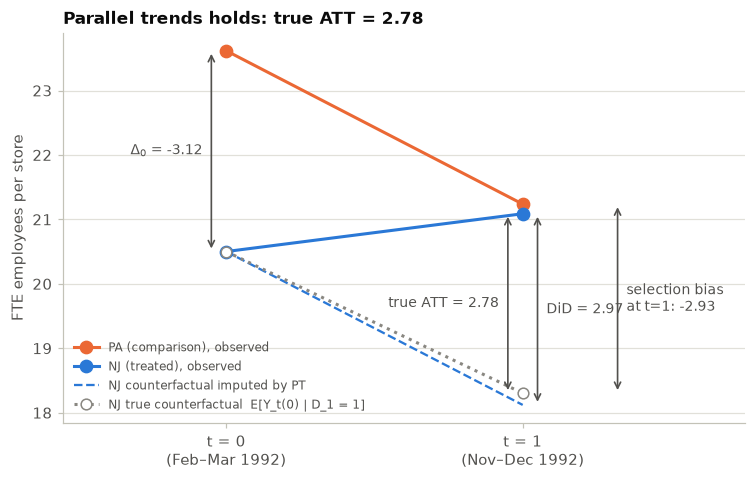

In [7]:
def plot_2x2(data, ax, title):
    T_, C_ = data.nj == 1, data.nj == 0
    pa = [data.y_pre[C_].mean(), data.y_post[C_].mean()]
    nj = [data.y_pre[T_].mean(), data.y_post[T_].mean()]
    cf_pt   = [nj[0], nj[0] + (pa[1] - pa[0])]                      # what PT imputes for NJ
    cf_true = [data.y_pre0[T_].mean(), data.y_post0[T_].mean()]     # E[Y_t(0) | D_1 = 1], God's eye
    x = [0, 1]
    ax.plot(x, pa, color=ORANGE, marker="o", ms=8, label="PA (comparison), observed")
    ax.plot(x, nj, color=BLUE, marker="o", ms=8, label="NJ (treated), observed")
    ax.plot(x, cf_pt, color=BLUE, ls="--", lw=1.5, label="NJ counterfactual imputed by PT")
    ax.plot(x, cf_true, color=MUTED, ls=":", lw=2, marker="o", ms=7, mfc="white",
            label="NJ true counterfactual  E[Y_t(0) | D_1 = 1]")

    def bracket(xpos, lo, hi, text, ha="left"):
        ax.annotate("", xy=(xpos, lo), xytext=(xpos, hi),
                    arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.1))
        ax.text(xpos + (0.03 if ha == "left" else -0.03), (lo + hi) / 2, text,
                ha=ha, va="center", fontsize=9, color=INK2)

    bracket(1.05, cf_pt[1], nj[1], f"DiD = {nj[1] - cf_pt[1]:.2f}")
    bracket(0.95, cf_true[1], nj[1], f"true ATT = {nj[1] - cf_true[1]:.2f}", ha="right")
    bracket(1.32, cf_true[1], pa[1], f"selection bias\nat t=1: {cf_true[1] - pa[1]:.2f}")
    bracket(-0.05, nj[0], pa[0], f"$\\Delta_0$ = {nj[0] - pa[0]:.2f}", ha="right")
    ax.set_xlim(-0.55, 1.75)
    ax.set_xticks(x, ["t = 0\n(Feb–Mar 1992)", "t = 1\n(Nov–Dec 1992)"])
    ax.set_ylabel("FTE employees per store")
    ax.set_title(title)
    ax.legend(loc="lower left", fontsize=8)

fig, ax = plt.subplots(figsize=(8, 4.6))
plot_2x2(ck, ax, f"Parallel trends holds: true ATT = {ATT:.2f}")
plt.show()

The dashed line (what PT imputes) runs almost on top of the gray dots (the truth). PT holds in
this simulation, so the imputed counterfactual *is* the counterfactual up to sampling noise, and
the DiD bracket matches the true-ATT bracket to within that noise. The selection-bias bracket at
$t=1$ is about as large as $\Delta_0$ at $t=0$, which is all that PT requires.

---
## 3 When the assumptions fail (slides 36–37, 4 min)

Two ways to break the design:
- **Non-parallel trends** (`delta`): NJ stores would have grown by an extra `delta` FTE anyway,
  say because the NJ economy was recovering faster.
- **Anticipation** (`antic`): the increase was scheduled two years in advance (slide 33). If NJ
  stores had already cut staff before the Feb–Mar survey, $Y_0 \neq Y_0(0)$ for NJ. Slide 36,
  comment 3: anticipation is harmless only if the $t = 0$ data are collected *before* units react.
  The training-program version of this is the *Ashenfelter dip* (Ashenfelter, 1978): trainees'
  earnings fall just before they enrol, so a before/after comparison overstates the gain.

### Exercise 3

For three scenarios, both assumptions hold, `delta = +1`, `antic = -1`, and for
$n \in \{410,\ 41{,}000,\ 410{,}000\}$, compute DiD and the true ATT. Before running it, use the
three-line proof above to predict the bias in each scenario.

,scenario,n,ATT (true),DiD,bias
0,both hold,410,2.741,2.615,-0.126
1,both hold,41000,2.752,2.678,-0.074
2,both hold,410000,2.754,2.728,-0.026
3,PT fails: delta = +1,410,2.940,5.220,2.280
4,PT fails: delta = +1,41000,2.748,3.747,0.999
5,PT fails: delta = +1,410000,2.752,3.767,1.015
6,NA fails: antic = -1,410,2.763,2.422,-0.341
7,NA fails: antic = -1,41000,2.742,3.632,0.890
8,NA fails: antic = -1,410000,2.751,3.732,0.981


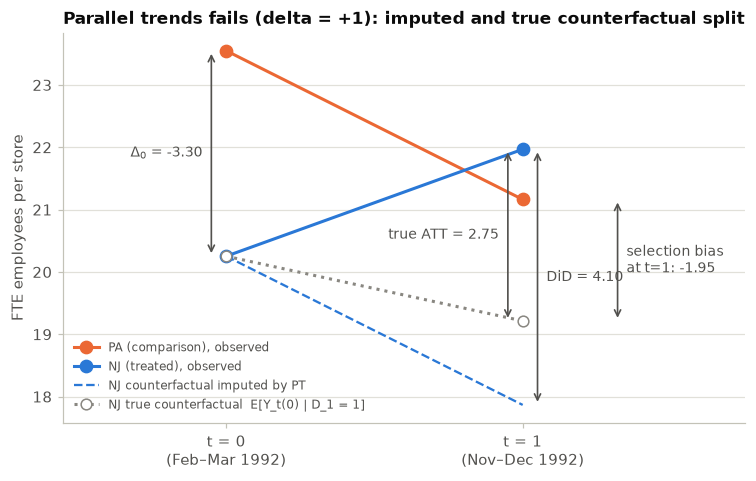

In [8]:
# ---- EXERCISE 3 -------------------------------------------------------------
rows = []
for label, kw in [("both hold", {}), ("PT fails: delta = +1", {"delta": 1.0}),
                  ("NA fails: antic = -1", {"antic": -1.0})]:
    for n_i in [410, 41_000, 410_000]:
        s = simulate_ck(n_i, **kw)
        Ti = s.nj == 1
        did_i = (s.y_post - s.y_pre)[Ti].mean() - (s.y_post - s.y_pre)[~Ti].mean()
        rows.append({"scenario": label, "n": n_i,
                     "ATT (true)": (s.y_post1 - s.y_post0)[Ti].mean(), "DiD": did_i})
res3 = pd.DataFrame(rows)
res3["bias"] = res3["DiD"] - res3["ATT (true)"]
display(res3)

fig, ax = plt.subplots(figsize=(8, 4.6))
plot_2x2(simulate_ck(delta=1.0), ax, "Parallel trends fails (delta = +1): imputed and true counterfactual split")
plt.show()
# -----------------------------------------------------------------------------

**What to see.** The proof predicts $\text{DiD} = \theta_{ATT} + \delta - a$, where $a$ is the
anticipation effect. At CK's sample size ($n = 410$) sampling noise is large enough to hide or
exaggerate the problem. From $n = 41{,}000$ on, both failures settle at a bias of about $+1$ that
**does not shrink with $n$**: more stores make us more confident in the wrong number. That is Part A's lesson again (A4), now
with trends instead of levels. In the figure the dashed (imputed) line no longer goes through the
gray dots, and the gap between them at $t=1$ is the bias: DiD now overshoots the true ATT.

**Can we test PT?** With two periods, no: the assumption is about $Y_1(0)$ for the treated, which
we never see. With more pre-periods we can compute *placebo* DiDs between pre-treatment periods
(pre-trends; you will do this in Section 4). Three cautions from the recent literature:
- Pre-trends are informative about pre-periods, not post-periods. Flat pre-trends are not a test of
  PT, and these tests have low power. Conditioning your analysis on "passing" them can make the
  bias worse (Roth, 2022).
- Better: say how large a post-period violation you are willing to entertain and report the
  resulting bounds (Rambachan & Roth, 2023).
- PT is not invariant to the scale of $Y$: PT in levels and PT in logs are different assumptions
  (Roth & Sant'Anna, 2023).

---
## 4 Staggered adoption: group-time ATTs (slides 41–43, 12 min)

Now $T$ periods and units that adopt at different dates (slide 41):
- $G$ is the first period a unit is treated; nobody is treated at $t=1$ (so $G \ge 2$), and
  $G = \infty$ means never treated. Treatment is absorbing.
- Potential outcomes are **paths** indexed by adoption date: $Y_t(g)$, with
  $Y_t = \sum_{g} Y_t(g)\,\mathbf 1\{G = g\}$.
- The building block (Callaway & Sant'Anna, 2021; slide 42) is the **group-time ATT**
  $$\theta_0(g,t) = E[\,Y_t(g) - Y_t(\infty) \mid G = g\,],$$
  the effect at calendar time $t$ for the cohort that adopted at $g$. It is allowed to differ
  freely across cohorts and over time.

### The data-generating process

A setting like CS (2021)'s own application: $n = 2{,}000$ counties, $T = 8$ years, states raising
the minimum wage at different dates. $Y = 100 \times \log(\text{teen employment})$, so effects are
roughly in percent.

| cohort | share | untreated level | $\theta_0(g, t)$ for $t \ge g$ |
|---|---|---|---|
| $G = 3$ | 0.20 | low | $-1.5\,[1 + 0.75(t-g)]$ |
| $G = 5$ | 0.30 | middle | $-1.0\,[1 + 0.75(t-g)]$ |
| $G = 7$ | 0.20 | higher | $-0.5\,[1 + 0.75(t-g)]$ |
| $G = \infty$ | 0.30 | highest | — |

Effects **grow with exposure** and **differ by cohort**. Cohorts differ in levels (PT allows
that) but share the same untreated trend, including a common recession in $t = 4$. So no
anticipation and parallel trends hold exactly. *The signs mimic CS's teen-employment estimates; the
magnitudes are made up.*

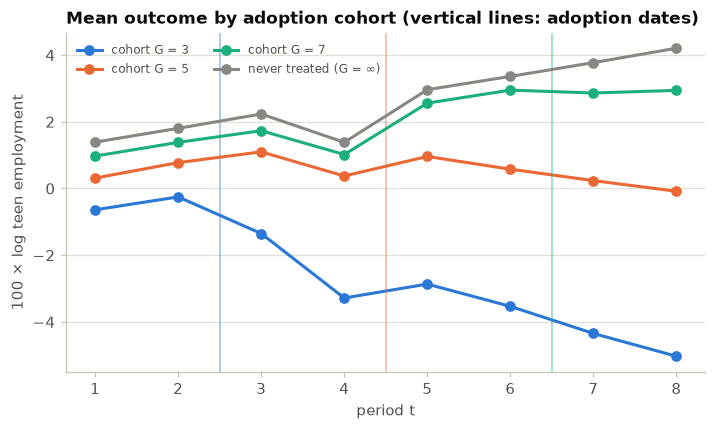

In [9]:
rng_s = np.random.default_rng(2021)
T_PER = 8
COHORT_SHARE = {3: 0.20, 5: 0.30, 7: 0.20, np.inf: 0.30}    # G = inf: never treated
COHORT_LEVEL = {3: -1.0, 5: 0.0, 7: 0.5, np.inf: 1.0}       # level differences: allowed by PT
EFFECT_SCALE = {3: 1.5, 5: 1.0, 7: 0.5}                      # early adopters respond more

def theta_true(g, t):
    '''True GT-ATT: zero before adoption, then growing with exposure e = t - g.'''
    if not np.isfinite(g) or t < g:
        return 0.0
    return -EFFECT_SCALE[g] * (1.0 + 0.75 * (t - g))

def simulate_staggered(n=2_000, rng=rng_s):
    G = rng.choice(list(COHORT_SHARE), size=n, p=list(COHORT_SHARE.values()))
    t = np.arange(1, T_PER + 1)
    alpha = np.vectorize(COHORT_LEVEL.get)(G) + rng.normal(0, 1, n)
    lam = 0.4 * t - 1.2 * (t == 4)                                       # common shocks; recession at t = 4
    Y_inf = alpha[:, None] + lam[None, :] + rng.normal(0, 1, (n, T_PER))  # Y_t(inf): untreated paths
    TAU = np.array([[theta_true(g, s) for s in t] for g in G])           # Y_t(G) - Y_t(inf)
    Y = Y_inf + TAU                                                      # observed: Y_t = Y_t(G)
    return pd.DataFrame({"id": np.repeat(np.arange(n), T_PER), "t": np.tile(t, n),
                         "G": np.repeat(G, T_PER), "y": Y.ravel(),
                         "y_inf": Y_inf.ravel(), "tau": TAU.ravel()})

panel = simulate_staggered()
COH_COLOR = {3: BLUE, 5: ORANGE, 7: AQUA, np.inf: MUTED}

fig, ax = plt.subplots()
for g, col in COH_COLOR.items():
    path = panel[panel.G == g].groupby("t").y.mean()
    ax.plot(path.index, path.values, color=col, marker="o", ms=6,
            label="never treated (G = ∞)" if np.isinf(g) else f"cohort G = {int(g)}")
    if np.isfinite(g):
        ax.axvline(g - 0.5, color=col, lw=1, alpha=0.5)
ax.set_xlabel("period t"); ax.set_ylabel("100 × log teen employment")
ax.set_title("Mean outcome by adoption cohort (vertical lines: adoption dates)")
ax.legend(fontsize=8, ncol=2); plt.show()

### Exercise 4.1 (5 min): estimate every $\theta_0(g,t)$ by hand

With no covariates, slide 45 says each GT-ATT is a 2×2: the cohort's change from the last
pre-treatment period $g-1$ to $t$, minus the comparison group's change over the same window:

$$\hat\theta(g,t) = \big[\bar Y_t - \bar Y_{g-1}\big]_{G = g} \;-\; \big[\bar Y_t - \bar Y_{g-1}\big]_{G \in \mathcal C_{gt}}.$$

Two choices of comparison set (slide 43):
- **never-treated:** $\mathcal C_{gt} = \{\infty\}$;
- **not-yet-treated:** $\mathcal C_{gt} = \{s : s > g \vee t\}$. Read $g \vee t$ as "$g$ max $t$",
  i.e. $\max\{g, t\}$. Everyone still untreated at both $g-1$ and $t$, never-treated included.

Write `att_gt_hat(g, t, comparison)` and compute all cells $t \neq g-1$. Cells with $t \ge g$ are
effects; cells with $t < g$ are **placebos** (pre-trends), which should be about zero here.

*Quick check before you code:* which cohorts are in $\mathcal C_{gt}$ for $(g,t) = (5,6)$? For
$(3, 8)$?

In [10]:
# ---- EXERCISE 4.1 -----------------------------------------------------------
wide = panel.pivot(index="id", columns="t", values="y")     # one row per county, one column per period
G_i  = panel.groupby("id").G.first()

def att_gt_hat(g, t, comparison="notyet"):
    '''Slide 45 without covariates: cohort trend minus comparison trend, both from g-1 to t.'''
    dy = wide[t] - wide[g - 1]                     # Y_t - Y_{g-1}, one number per county
    treated = G_i == g
    if comparison == "never":
        comp = np.isinf(G_i)                       # C_gt = {inf}
    else:
        comp = G_i > max(g, t)                     # C_gt = {s : s > g v t}  (slide 43)
    return dy[treated].mean() - dy[comp].mean()

rows = []
for g in [3, 5, 7]:
    for t in range(1, T_PER + 1):
        if t == g - 1:
            continue                               # base period: zero by construction
        rows.append({"g": g, "t": t, "e": t - g, "truth": theta_true(g, t),
                     "not-yet-treated": att_gt_hat(g, t),
                     "never-treated": att_gt_hat(g, t, "never"),
                     "comparison cohorts (not-yet)": ", ".join(
                         "∞" if np.isinf(s) else str(int(s)) for s in sorted(G_i[G_i > max(g, t)].unique()))})
gt = pd.DataFrame(rows)

print("Post-treatment cells (t >= g):")
display(gt[gt.e >= 0].set_index(["g", "t"]))
print("Placebo cells (t < g): largest |estimate| =",
      f"{gt.loc[gt.e < 0, 'not-yet-treated'].abs().max():.3f}")
# -----------------------------------------------------------------------------

Post-treatment cells (t >= g):


e  truth  not-yet-treated  never-treated comparison cohorts (not-yet)
g t                                                                       
3 3  0 -1.500           -1.468         -1.529                      5, 7, ∞
  4  1 -2.625           -2.633         -2.612                      5, 7, ∞
  5  2 -3.750           -3.780         -3.773                         7, ∞
  6  3 -4.875           -4.844         -4.840                         7, ∞
  7  4 -6.000           -6.065         -6.065                            ∞
  8  5 -7.125           -7.180         -7.180                            ∞
5 5  0 -1.000           -0.978         -0.993                         7, ∞
  6  1 -1.750           -1.756         -1.774                         7, ∞
  7  2 -2.500           -2.529         -2.529                            ∞
  8  3 -3.250           -3.280         -3.280                            ∞
7 7  0 -0.500           -0.500         -0.500                            ∞
  8  1 -0.875           -0.852         -0.852                            ∞

Placebo cells (t < g): largest |estimate| = 0.090


**Reading the table.**
- Every post-treatment cell is recovered with either comparison group: PT holds for both here.
- The comparison set **shrinks over time** under not-yet-treated: for $(5,6)$ it is
  $\{7, \infty\}$, for $(3,8)$ and $(5,8)$ only $\{\infty\}$, because cohort 7 is treated by then.
  Not-yet-treated buys precision early on and coincides with never-treated at the end.
- Already-treated units are **never** used as controls. Keep that in mind for 4.3.
- Slide 44's parallel-trends assumption is stated only for $t \ge g$. The placebo cells check PT in
  periods where it is *not* assumed. That is why they are a diagnostic and not a test.

Which comparison group to use is a substantive choice. Never-treated units may differ more (e.g. a
particular region); not-yet-treated units may have timed their adoption on outcomes. State which
PT you assume and why (Baker et al., 2026).

### Exercise 4.2 (4 min): from 21 cells to an event study

Nobody reads 21 numbers. Slide 42 aggregates by **event time** $e = t - g$:

$$\theta_{es}(e) = \sum_{g} P(G = g \mid G + e \le T)\;\theta_0(g, g+e).$$

The weights are the cohort shares *among the cohorts we observe $e$ periods after adoption*. Build
the event study for $e = -5, \dots, 5$ from the not-yet-treated cells and plot it against the truth.

*A note on the formula, flagged because the slide states it for $e \ge 0$:* for leads ($e < 0$) a
cohort must also satisfy $g + e \ge 1$ to be observed, and $e = -1$ is the reference period (zero
by construction). My reading is that the weights are then the shares among cohorts with a cell at
$e$, which is what the code does. This also matches `moderndid` in the optional cell below.

,cohorts,weights,truth,estimate
e,,,,
-5,[7],[1.0],0.000,-0.010
-4,"[5, 7]","[0.61, 0.39]",0.000,-0.064
-3,"[5, 7]","[0.61, 0.39]",0.000,0.020
-2,"[3, 5, 7]","[0.29, 0.43, 0.28]",0.000,-0.016
0,"[3, 5, 7]","[0.29, 0.43, 0.28]",-1.006,-0.987
1,"[3, 5, 7]","[0.29, 0.43, 0.28]",-1.761,-1.759
2,"[3, 5]","[0.4, 0.6]",-3.006,-3.035
3,"[3, 5]","[0.4, 0.6]",-3.907,-3.912
4,[3],[1.0],-6.000,-6.065


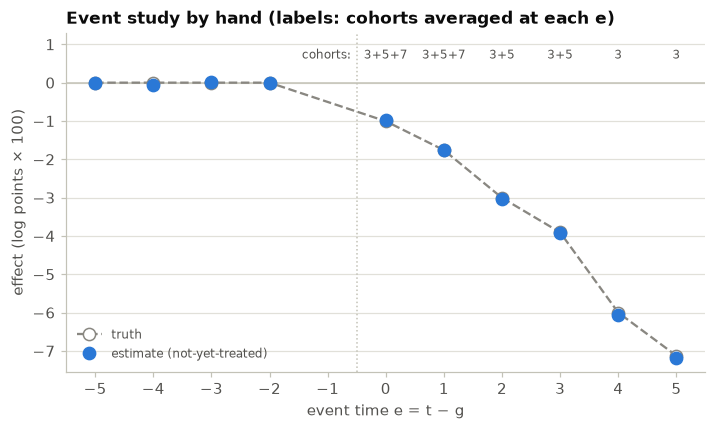

In [11]:
# ---- EXERCISE 4.2 -----------------------------------------------------------
n_g = G_i.value_counts()                                     # cohort sizes
rows = []
for e in range(-5, 6):
    if e == -1:
        continue
    cells = gt[gt.e == e]                                    # cohorts observed at event time e
    w = n_g.reindex(cells.g).to_numpy(dtype=float)
    w /= w.sum()                                             # P(G = g | cohort observed at e)
    rows.append({"e": e, "cohorts": cells.g.tolist(), "weights": np.round(w, 2).tolist(),
                 "truth": (w * cells.truth).sum(), "estimate": (w * cells["not-yet-treated"]).sum()})
es = pd.DataFrame(rows).set_index("e")
display(es)

fig, ax = plt.subplots()
ax.axhline(0, color=AXIS, lw=1); ax.axvline(-0.5, color=AXIS, lw=1, ls=":")
ax.plot(es.index, es.truth, color=MUTED, ls="--", lw=1.5, marker="o", ms=8, mfc="white", label="truth")
ax.plot(es.index, es.estimate, color=BLUE, ls="none", marker="o", ms=8, label="estimate (not-yet-treated)")
for e, row in es.iterrows():
    if e >= 0:                                              # one row of labels along the top
        ax.text(e, 0.55, "+".join(str(int(g)) for g in row.cohorts),
                ha="center", va="bottom", fontsize=8, color=INK2)
ax.text(-0.6, 0.55, "cohorts:", ha="right", va="bottom", fontsize=8, color=INK2)
ax.set_ylim(top=1.3)
ax.set_xticks(range(-5, 6)); ax.set_xlabel("event time e = t − g")
ax.set_ylabel("effect (log points × 100)")
ax.set_title("Event study by hand (labels: cohorts averaged at each e)")
ax.legend(loc="lower left", fontsize=8); plt.show()
# -----------------------------------------------------------------------------

**What to see.** The event study is flat before $e=0$ and falls after, as it should. But look at
the labels: at $e = 0, 1$ all three cohorts contribute; at $e = 2, 3$ only cohorts 3 and 5; at
$e = 4, 5$ only cohort 3, the one with the largest effects. Part of the steep slope after $e = 3$ is
a **change in who is averaged**, not a change over time in anyone's effect. When you read dynamics off an event
study, check its composition. CS (2021) suggest balancing the sample in event time
(`balance_e` in their software) when dynamics are the question.

Other aggregations answer other questions: by cohort, by calendar time, or one overall number.
CS (2021) recommend the cohort-based overall average, in which every treated unit counts once.
Choose the aggregation **before** looking at the numbers.

### 4.3 Why not just run TWFE? (2 min)

The regression most papers would run is $Y_{it} = \alpha_i + \lambda_t + \beta D_{it} + \varepsilon_{it}$.
In a balanced panel, Frisch–Waugh–Lovell says $\hat\beta$ is the slope after two-way demeaning both
$Y$ and $D$, so we can compute it in three lines.

In [12]:
panel["D"] = (panel.t >= panel.G).astype(int)

def twoway_demean(df, col):
    return (df[col] - df.groupby("id")[col].transform("mean")
            - df.groupby("t")[col].transform("mean") + df[col].mean())

y_dd, D_dd = twoway_demean(panel, "y"), twoway_demean(panel, "D")
beta_twfe = (y_dd * D_dd).sum() / (D_dd ** 2).sum()

post = gt[gt.e >= 0]
w_post = n_g.reindex(post.g).to_numpy(dtype=float)
cs_simple = (w_post * post["not-yet-treated"]).sum() / w_post.sum()

# One of the 2x2s hidden inside TWFE: cohort 7 around its adoption, periods {5,6} -> {7,8}
m = panel.groupby(["G", "t"]).y.mean()
change = lambda g: m.loc[g, [7, 8]].mean() - m.loc[g, [5, 6]].mean()
display(pd.Series({
    "true average effect, treated county-periods": panel.loc[panel.D == 1, "tau"].mean(),
    "CS: simple aggregation of GT-ATTs": cs_simple,
    "static TWFE beta": beta_twfe,
}).to_frame("estimate"))
pd.Series({
    "true effect, cohort 7 in t = 7-8": np.mean([theta_true(7, 7), theta_true(7, 8)]),
    "clean 2x2: cohort 7 vs never-treated": change(7) - change(np.inf),
    "forbidden 2x2: cohort 7 vs ALREADY-treated cohort 3": change(7) - change(3),
}).to_frame("estimate")

,estimate
"true average effect, treated county-periods",-2.876
CS: simple aggregation of GT-ATTs,-2.886
static TWFE beta,-1.431


,estimate
"true effect, cohort 7 in t = 7-8",-0.688
clean 2x2: cohort 7 vs never-treated,-0.680
forbidden 2x2: cohort 7 vs ALREADY-treated cohort 3,1.636


**What happened.** Every $\theta_0(g,t)$ is negative and PT holds exactly, yet TWFE recovers only
about half of the average effect. $\hat\beta^{TWFE}$ is a weighted average of **all** 2×2
comparisons in the data, including "forbidden" ones that use already-treated cohorts as controls
(Goodman-Bacon, 2021). In the last table, cohort 3's effect is still *growing* between the two
windows. Used as a control, that growth is read as a "trend" and subtracted. The forbidden 2×2
turns a true effect of about $-0.7$ into about $+1.6$. In other terms, some $\theta_0(g,t)$ get
negative weight (de Chaisemartin & D'Haultfœuille, 2020).

The problem is staggering **combined with** heterogeneous or dynamic effects. With a constant
effect the forbidden comparisons are harmless. That is why the GT-ATTs are the building blocks:
each one is a clean 2×2, and the aggregation weights are explicit and non-negative.

### Optional: check against `moderndid` (Python port of R's `did`)

`moderndid.att_gt` computes the same cells, plus influence-function standard errors and uniform
bands. It needs Python ≥ 3.11 (`pip install moderndid`). The cell skips itself if the package is
missing. See the Econ 521 lab (Lab 08) for a full walkthrough on the Medicaid data.

In [13]:
try:
    import moderndid as md
except ImportError:
    md = None
    print("moderndid not installed; skipping (pip install moderndid).")

if md is not None:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        p_md = panel.assign(G0=np.where(np.isinf(panel.G), 0, panel.G).astype(int))   # 0 = never treated
        cs = md.att_gt(data=p_md, yname="y", tname="t", idname="id", gname="G0",
                       control_group="notyettreated", base_period="universal", boot=False)
        es_md = md.aggte(cs, type="dynamic")
    chk = (pd.DataFrame({"g": cs.groups.astype(int), "t": cs.times.astype(int), "moderndid": cs.att_gt})
             .merge(gt, on=["g", "t"]))
    print(f"max |moderndid - by hand| over {len(chk)} GT cells: "
          f"{(chk.moderndid - chk['not-yet-treated']).abs().max():.1e}")
    out = pd.DataFrame({"e": es_md.event_times.astype(int), "moderndid": es_md.att_by_event,
                        "SE": es_md.se_by_event}).set_index("e")
    display(out.join(es[["estimate"]].rename(columns={"estimate": "by hand"})).loc[-5:5].T)

max |moderndid - by hand| over 21 GT cells: 4.4e-16


e,-5,-4,-3,-2,-1,0,1,2,3,4,5
moderndid,-0.010,-0.064,0.020,-0.016,0.000,-0.987,-1.759,-3.035,-3.912,-6.065,-7.180
SE,0.090,0.057,0.058,0.047,NaN,0.047,0.050,0.063,0.064,0.088,0.090
by hand,-0.010,-0.064,0.020,-0.016,NaN,-0.987,-1.759,-3.035,-3.912,-6.065,-7.180


---
## 5 Conditional parallel trends with high-dimensional $Z$ (slides 44–46, 13 min)

### 5.1 Why covariates, and why so many

Unconditional PT is often hard to believe. States that raise the minimum wage tend to have
different industry mixes, demographics and recent labour-market histories, and those
characteristics move employment *trends*, not just levels. The slides' fix (slide 44) is to
assume PT only among units with the same pre-treatment covariates:

- **Conditional PT:** $E[Y_t(\infty) - Y_{t-1}(\infty) \mid G = g, Z] = E[Y_t(\infty) - Y_{t-1}(\infty) \mid G = c, Z]$ for $c\in\mathcal C_{gt}$, $t \ge g$;
- **Overlap:** $P(G = g \mid Z) > 0$. For the ATT, the part that matters most is that comparison
  units exist at every $Z$ where treated units live. This is the same asymmetry as Part A, A3.

Then (slide 45) $\theta_0(g,t) = E\big[Y_t - Y_{g-1} - \mu_{gt,0}(1, Z) \mid G = g\big]$, with the
**comparison trend regression** $\mu_{gt,0}(1, Z) = E[Y_t - Y_{g-1} \mid G \in \mathcal C_{gt}, Z]$.
This is the DiD version of matching: compare each treated unit's trend with the predicted
untreated trend of comparison units *with the same $Z$* (Heckman, Ichimura & Todd, 1997).

**Why "high-dimensional" is the normal case, not a corner case.** The credibility of conditional PT
grows with the richness of $Z$. Thirty county characteristics, plus their squares and pairwise
interactions, already make $30 + 30 + 435 = 495$ regressors. The cell-by-cell approach is hopeless
(Part A, A4.2), and in a staggered design you need one $\mu_{gt,0}$ **for every $(g,t)$ cell**.
This is slide 46: identification is easy to write down, and the difficulty is estimating the
nuisance.

To keep the code readable we work with one cell, the 2×2 ($g = 2$, $t = 2$, $\mathcal C = \{\infty\}$),
where everything reduces to
$$\theta_{ATT} = E\big[\Delta Y - \mu_0(Z) \mid D = 1\big], \qquad \mu_0(Z) = E[\Delta Y \mid D = 0, Z],\quad \Delta Y = Y_2 - Y_1.$$
For any $(g,t)$ in Section 4, set $\Delta Y = Y_t - Y_{g-1}$ and $D = \mathbf 1\{G = g\}$ on the sample
$\{G = g\} \cup \{G \in \mathcal C_{gt}\}$, and the same code applies.

### The data-generating process

$n = 1{,}000$ counties and $p = 300$ pre-treatment characteristics $Z$, correlated with their
neighbours ($\rho = 0.5$). **Only 8 of them matter, and the researcher does not know which:**
- selection: $P(D = 1 \mid Z) = \Lambda(-0.3 + 0.25\,(Z_1 + \dots + Z_8))$;
- untreated trend: $\mu_0(Z) = 1 + (Z_1 + Z_2 + Z_3) + 0.25\,(Z_4 + \dots + Z_8)$, the same for
  treated and untreated units at a given $Z$, so **conditional PT holds**; unconditional PT fails
  because treated counties have higher $Z_1,\dots,Z_8$;
- effect: $\tau(Z) = -1 - 0.5\,Z_1$, heterogeneous.

In [14]:
N_HD, P_HD, RHO = 1_000, 300, 0.5

def make_coefs(p):
    '''Only 8 of p covariates matter; the researcher does not know which.'''
    beta, gamma = np.zeros(p), np.zeros(p)
    beta[:3], gamma[:3] = 1.0, 0.25          # Z1-Z3: strong trend shifters
    beta[3:8], gamma[3:8] = 0.25, 0.25       # Z4-Z8: weak trend shifters, same pull on selection
    return beta, gamma

def simulate_hd(n=N_HD, p=P_HD, rng=None):
    beta, gamma = make_coefs(p)
    E = rng.normal(size=(n, p))
    Z = np.empty_like(E); Z[:, 0] = E[:, 0]
    for k in range(1, p):                                    # neighbouring covariates correlate
        Z[:, k] = RHO * Z[:, k - 1] + np.sqrt(1 - RHO**2) * E[:, k]
    e   = 1 / (1 + np.exp(-(-0.3 + Z @ gamma)))              # propensity P(D = 1 | Z)
    D   = rng.binomial(1, e)
    mu0 = 1.0 + Z @ beta                                     # E[dY(0) | Z], same for D = 0, 1
    tau = -1.0 - 0.5 * Z[:, 0]                               # heterogeneous effect
    dY  = mu0 + D * tau + rng.normal(0, 1, n)                # observed Y_2 - Y_1
    return Z, D, dY, tau, e, mu0

rng_h = np.random.default_rng(524)
# Population ATT from one very large draw (only Z1-Z8 matter, so a small p gives the same ATT)
_, D_big, _, tau_big, e_big, _ = simulate_hd(200_000, 25, rng_h)
TRUE_ATT = tau_big[D_big == 1].mean()
print(f"true ATT = {TRUE_ATT:.3f};  share treated = {D_big.mean():.2f};  "
      f"propensity 1st-99th pct = [{np.quantile(e_big, .01):.2f}, {np.quantile(e_big, .99):.2f}]")

true ATT = -1.112;  share treated = 0.44;  propensity 1st-99th pct = [0.05, 0.91]


### Exercise 5.1 (2 min)

Draw one sample with `simulate_hd(rng=rng_h)`. Compute (i) the unconditional DiD
$\bar{\Delta Y}_{D=1} - \bar{\Delta Y}_{D=0}$ and (ii) the **oracle** estimator that uses the
true $\mu_0(Z)$: $\frac{1}{n_1}\sum_{D_i=1}\{\Delta Y_i - \mu_0(Z_i)\}$. Compare both with the truth.

In [15]:
# ---- EXERCISE 5.1 -----------------------------------------------------------
Z, D, dY, tau, e, mu0 = simulate_hd(rng=rng_h)
T1, C0 = D == 1, D == 0
unconditional = dY[T1].mean() - dY[C0].mean()
oracle        = (dY[T1] - mu0[T1]).mean()
pd.Series({"true ATT (population)": TRUE_ATT, "ATT in this sample": tau[T1].mean(),
           "unconditional DiD": unconditional, "oracle (true mu_0)": oracle,
           "n treated / n comparison": f"{T1.sum()} / {C0.sum()}"})
# -----------------------------------------------------------------------------

true ATT (population)          -1.112
ATT in this sample             -1.102
unconditional DiD               1.180
oracle (true mu_0)             -1.146
n treated / n comparison    447 / 553
dtype: object

The unconditional DiD gets the **sign wrong**. Treated counties were on faster employment trends
for reasons captured by $Z$, and the simple comparison credits that to the policy. The oracle
nails it: identification works. What remains is a pure *estimation* problem: learn
$\mu_0(\cdot)$, a function of 300 variables, from about 550 comparison counties.

### 5.2 Three plug-in estimators (3 min)

1. **"TWFE + $Z \times$ Post"**: OLS of $\Delta Y$ on $D$ and all of $Z$. This is what adding
   covariates to the TWFE regression amounts to with two periods.
2. **Plug-in OLS**: fit $\mu_0$ by OLS on comparison units, impute for the treated, average the
   residuals (the outcome-regression form of slide 45).
3. **Plug-in LASSO**: the same with `LassoCV`, the Lecture 1 tool for $p$ large.

In [16]:
# ---- EXERCISE 5.2 -----------------------------------------------------------
twfe_x = LinearRegression().fit(np.column_stack([D, Z]), dY).coef_[0]

ols0   = LinearRegression().fit(Z[C0], dY[C0])
or_ols = (dY[T1] - ols0.predict(Z[T1])).mean()

las0     = LassoCV(cv=5).fit(Z[C0], dY[C0])
or_lasso = (dY[T1] - las0.predict(Z[T1])).mean()

beta_true, _ = make_coefs(P_HD)
display(pd.DataFrame({"true beta": beta_true[:8], "LASSO": las0.coef_[:8],
                      "OLS": ols0.coef_[:8]}, index=[f"Z{j}" for j in range(1, 9)]).T)
print(f"LASSO keeps {np.sum(las0.coef_ != 0)} of {P_HD} covariates (alpha = {las0.alpha_:.3f}); "
      f"sum of coefficients on Z1-Z8: LASSO {las0.coef_[:8].sum():.2f} vs truth {beta_true[:8].sum():.2f}")
print(f"average error mu_0 - mu_hat (LASSO):  comparison counties {np.mean(mu0[C0] - las0.predict(Z[C0])):+.3f}"
      f"   treated counties {np.mean(mu0[T1] - las0.predict(Z[T1])):+.3f}")
pd.Series({"ATT in this sample": tau[T1].mean(), "oracle": oracle,
           "1. TWFE + Z x Post (OLS)": twfe_x, "2. plug-in OLS": or_ols, "3. plug-in LASSO": or_lasso})
# -----------------------------------------------------------------------------

,Z1,Z2,Z3,Z4,Z5,Z6,Z7,Z8
true beta,1.000,1.000,1.000,0.250,0.250,0.250,0.250,0.250
LASSO,0.972,0.947,1.012,0.030,0.318,0.152,0.229,0.209
OLS,1.146,0.920,1.088,0.125,0.311,0.210,0.203,0.423


LASSO keeps 10 of 300 covariates (alpha = 0.101); sum of coefficients on Z1-Z8: LASSO 3.87 vs truth 4.25
average error mu_0 - mu_hat (LASSO):  comparison counties -0.001   treated counties +0.220


ATT in this sample         -1.102
oracle                     -1.146
1. TWFE + Z x Post (OLS)   -1.178
2. plug-in OLS             -1.130
3. plug-in LASSO           -0.926
dtype: float64

**Reading the three numbers.** *(One draw; the Monte Carlo in 5.4 says which patterns are
systematic.)*

1. **TWFE + Z×Post** is not built to target the ATT, even though $\mu_0$ here is linear. With
   heterogeneous effects, OLS averages them with its own variance-based weights instead of the
   ATT's weights. This is the lesson of Angrist (1998) in Part A; Słoczyński (2022, *REStat*)
   gives the continuous-covariate version. In one draw the gap can hide in the noise; the Monte
   Carlo in 5.4 shows that it is systematic. Prefer estimators that target the ATT by construction.
2. **Plug-in OLS** is unbiased here because $\mu_0$ is linear, but it spends 300 coefficients on
   about 550 observations, and its noisy imputations feed straight into $\hat\theta$. Look at its
   coefficient table: the $p/n$ law from Lab 1 (Cattaneo, Jansson & Newey, 2018). With
   $p \ge n_0$ it is not even defined.
3. **Plug-in LASSO** fixes the variance by **shrinking** toward zero. Most of the loss falls on the
   weak shifters $Z_4$–$Z_8$, and those are variables on which treated and comparison counties
   differ. Look at the last printed line. Because LASSO includes an intercept, its errors average
   out on the comparison counties it was trained on. On the *treated* counties it systematically
   under-predicts the untreated trend, and that error passes straight into the estimate, pushing it
   toward zero. That is **regularization bias**.

Why plug-in LASSO is fragile, in one derivative: write
$\theta(\mu) = E[D\{\Delta Y - \mu(Z)\}]/P(D=1)$ and perturb $\mu = \mu_0 + r\delta$. Then
$\partial_r \theta = -E[\delta(Z) \mid D = 1] \neq 0$. Any systematic error in $\hat\mu$ on the treated
covariate distribution passes **one for one** into $\hat\theta$. LASSO's error is systematic by
design, since it shrinks toward zero. The same logic is behind post-double-selection (Belloni,
Chernozhukov & Hansen, 2014).

### 5.3 The fix: a doubly robust, Neyman-orthogonal score with cross-fitting (4 min)

Sant'Anna & Zhao (2020) give the doubly robust DiD estimand for panel data:

$$
\theta_{ATT} = \frac{1}{P(D=1)}\,E\Big[\Big(D - (1-D)\,\frac{e(Z)}{1-e(Z)}\Big)\big(\Delta Y - \mu_0(Z)\big)\Big],
\qquad e(Z) = P(D = 1 \mid Z).
$$

*Reading it:* the $D$ part is the plug-in estimator. The second part takes the comparison units'
residuals $\Delta Y - \hat\mu_0(Z)$, reweights them by the odds $e/(1-e)$ so that they look like
the treated (Abadie, 2005, IPW-DiD), and subtracts them. Whatever $\hat\mu_0$ got wrong on
treated-like covariates shows up in those reweighted residuals and is removed.

**Orthogonality in two lines** (the property the DML block of the course is built on). Perturb
$\mu_0 \to \mu_0 + r\delta$ and use $E[D \mid Z] = e(Z)$:
$$
\partial_r\, E\Big[\Big(D - (1-D)\tfrac{e}{1-e}\Big)(\Delta Y - \mu_0 - r\delta)\Big]
= -E\Big[\Big(e(Z) - (1-e(Z))\tfrac{e(Z)}{1-e(Z)}\Big)\delta(Z)\Big] = 0 .
$$
Perturbing $e$ instead multiplies $(1-D)(\Delta Y - \mu_0(Z))$, whose mean given $Z$ is zero by the
definition of $\mu_0$. First-order errors in **either** nuisance do not move the estimate. Only
the *product* of the two errors does, so each nuisance can be learned at a slower rate, about
$n^{-1/4}$ (Chernozhukov et al., 2018). The score is also **doubly robust**: it is correct if
*either* $\mu_0$ or $e$ is correct (Robins, Rotnitzky & Zhao, 1994).

**Cross-fitting.** Fit $\hat\mu_0, \hat e$ on $K-1$ folds and evaluate them on the held-out fold, so
no observation is scored by a model that was trained on it. With cross-fitting this is the DML-DiD
estimator of Chang (2020). The standard error comes from the influence function
$\psi_i = \big[(D_i - (1-D_i)\hat e_i/(1-\hat e_i))(\Delta Y_i - \hat\mu_i) - D_i\hat\theta\big]/\hat P(D=1)$.

### Exercise 5.3

Complete `dr_did` and run it with `LassoCV` for $\mu_0$ and an L1-penalized logit for $e$. Does the
95% CI cover the truth?

In [17]:
# ---- EXERCISE 5.3 -----------------------------------------------------------
def dr_did(Z, D, dY, mu_learner, e_learner, K=5, seed=0, trim=0.01):
    '''Cross-fitted doubly robust DiD for the ATT (Sant'Anna & Zhao, 2020; Chang, 2020).
    mu_learner : any sklearn regressor, for mu_0(Z) = E[dY | D = 0, Z] (fit on comparison units)
    e_learner  : any sklearn classifier, for e(Z) = P(D = 1 | Z)
    Returns (theta_hat, se), se from the influence function.'''
    n = len(D)
    mu_hat, e_hat = np.empty(n), np.empty(n)
    for train, test in KFold(K, shuffle=True, random_state=seed).split(Z):
        ctrl = train[D[train] == 0]
        mu_hat[test] = clone(mu_learner).fit(Z[ctrl], dY[ctrl]).predict(Z[test])
        e_hat[test]  = clone(e_learner).fit(Z[train], D[train]).predict_proba(Z[test])[:, 1]
    e_hat = np.clip(e_hat, trim, 1 - trim)                  # guard against extreme odds
    p1 = D.mean()
    w = D - (1 - D) * e_hat / (1 - e_hat)                   # treated: +1; comparison: -odds
    theta = np.mean(w * (dY - mu_hat)) / p1
    psi = (w * (dY - mu_hat) - D * theta) / p1              # influence function
    return theta, psi.std() / np.sqrt(n)

mu_learner = LassoCV(cv=5)
e_learner  = LogisticRegressionCV(Cs=np.logspace(-2, 0, 6), cv=3, solver="liblinear",
                                  scoring="neg_log_loss", max_iter=1000, **L1CV)
theta_dml, se_dml = dr_did(Z, D, dY, mu_learner, e_learner)

pd.Series({"ATT (population)": TRUE_ATT, "plug-in LASSO": or_lasso, "DR-DML (LASSO)": theta_dml,
           "DR-DML SE": se_dml, "95% CI low": theta_dml - 1.96 * se_dml,
           "95% CI high": theta_dml + 1.96 * se_dml})
# -----------------------------------------------------------------------------

ATT (population)   -1.112
plug-in LASSO      -0.926
DR-DML (LASSO)     -1.163
DR-DML SE           0.117
95% CI low         -1.392
95% CI high        -0.934
dtype: float64

### 5.4 Is this luck? A Monte Carlo across $p$ (3 min; the cell takes about a minute)

One draw proves nothing. We repeat everything 200 times for $p \in \{25, 300, 500\}$ with $n = 1{,}000$
fixed (so $n_0 \approx 560$), and record bias, standard deviation, RMSE, average reported SE, and the
coverage of nominal 95% intervals. For TWFE + Z×Post we use the usual OLS standard error; for the
plug-ins, the SE a practitioner would naively report, treating $\hat\mu_0$ as known.

*Shortcut to keep it fast:* the LASSO penalty and the logit's $C$ are tuned once per $p$ on a
pilot draw and then held fixed. In an application you would cross-validate every time, as in 5.3.

In [18]:
def run_mc(p, R=200, n=N_HD, seed=0):
    rng_mc = np.random.default_rng(seed)
    Zp, Dp, dYp, *_ = simulate_hd(n, p, rng_mc)                       # pilot draw: tune once
    alpha = LassoCV(cv=5).fit(Zp[Dp == 0], dYp[Dp == 0]).alpha_
    C_pen = float(np.ravel(clone(e_learner).fit(Zp, Dp).C_)[0])
    rows = []
    for r in range(R):
        Zr, Dr, dYr, *_ = simulate_hd(n, p, rng_mc)
        t1, c0 = Dr == 1, Dr == 0
        unc = (dYr[t1].mean() - dYr[c0].mean(),
               np.sqrt(dYr[t1].var() / t1.sum() + dYr[c0].var() / c0.sum()))
        X = np.column_stack([np.ones(n), Dr, Zr])                       # TWFE + Z x Post = OLS of dY on (1, D, Z)
        XtX_inv = np.linalg.inv(X.T @ X)
        b = XtX_inv @ (X.T @ dYr)
        s2 = np.sum((dYr - X @ b) ** 2) / (n - X.shape[1])
        twx = (b[1], np.sqrt(s2 * XtX_inv[1, 1]))
        if c0.sum() > p + 1:                                            # OLS needs n_0 > p
            res = dYr[t1] - LinearRegression().fit(Zr[c0], dYr[c0]).predict(Zr[t1])
            ols = (res.mean(), res.std() / np.sqrt(t1.sum()))
        else:
            ols = (np.nan, np.nan)
        res = dYr[t1] - Lasso(alpha=alpha).fit(Zr[c0], dYr[c0]).predict(Zr[t1])
        las = (res.mean(), res.std() / np.sqrt(t1.sum()))               # naive: treats mu_hat as known
        dml = dr_did(Zr, Dr, dYr, Lasso(alpha=alpha),
                     LogisticRegression(C=C_pen, solver="liblinear", **L1), seed=r)
        for name, (est, se) in [("unconditional DiD", unc), ("TWFE + Z x Post", twx), ("plug-in OLS", ols),
                                ("plug-in LASSO", las), ("DR-DML (LASSO)", dml)]:
            rows.append({"p": p, "rep": r, "estimator": name, "estimate": est, "se": se})
    return pd.DataFrame(rows)

mc = pd.concat([run_mc(p, seed=p) for p in [25, 300, 500]], ignore_index=True)
mc["covers"] = (mc.estimate - 1.96 * mc.se <= TRUE_ATT) & (TRUE_ATT <= mc.estimate + 1.96 * mc.se)
summary = mc.groupby(["p", "estimator"], sort=False).agg(
    bias=("estimate", lambda x: x.mean() - TRUE_ATT), sd=("estimate", "std"),
    avg_se=("se", "mean"), coverage=("covers", "mean"))
summary["rmse"] = np.sqrt(summary.bias**2 + summary.sd**2)
summary[["bias", "sd", "rmse", "avg_se", "coverage"]]

bias    sd  rmse  avg_se  coverage
p   estimator                                             
25  unconditional DiD  2.068 0.145 2.073   0.159     0.000
    TWFE + Z x Post    0.075 0.072 0.104   0.074     0.830
    plug-in OLS       -0.012 0.077 0.078   0.054     0.815
    plug-in LASSO      0.064 0.076 0.100   0.053     0.690
    DR-DML (LASSO)    -0.013 0.091 0.092   0.091     0.975
300 unconditional DiD  2.086 0.148 2.091   0.158     0.000
    TWFE + Z x Post    0.083 0.094 0.125   0.087     0.830
    plug-in OLS        0.002 0.120 0.120   0.074     0.770
    plug-in LASSO      0.150 0.085 0.173   0.052     0.295
    DR-DML (LASSO)     0.016 0.096 0.097   0.091     0.940
500 unconditional DiD  2.083 0.166 2.090   0.158     0.000
    TWFE + Z x Post    0.087 0.109 0.139   0.104     0.850
    plug-in OLS        0.002 0.240 0.241   0.154     0.780
    plug-in LASSO      0.198 0.081 0.214   0.053     0.130
    DR-DML (LASSO)     0.019 0.096 0.098   0.096     0.945

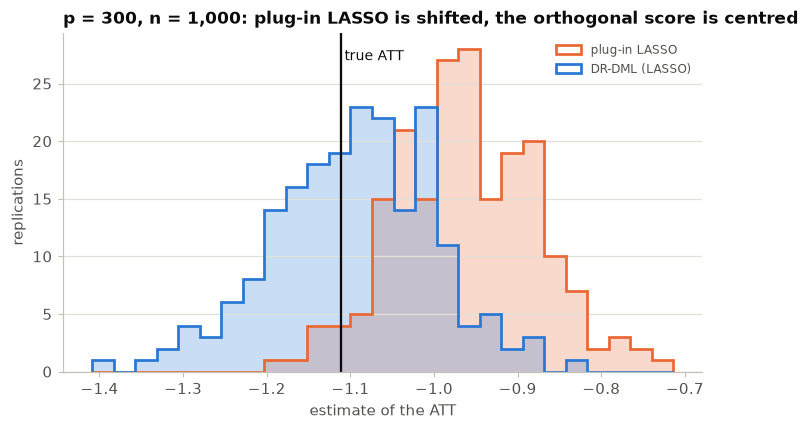

In [19]:
sub = mc[(mc.p == 300) & mc.estimator.isin(["plug-in LASSO", "DR-DML (LASSO)"])]
bins = np.linspace(sub.estimate.min() - 0.02, sub.estimate.max() + 0.02, 28)
fig, ax = plt.subplots()
for name, col in [("plug-in LASSO", ORANGE), ("DR-DML (LASSO)", BLUE)]:
    x = sub.loc[sub.estimator == name, "estimate"]
    ax.hist(x, bins=bins, color=col, alpha=0.25, histtype="stepfilled")
    ax.hist(x, bins=bins, color=col, histtype="step", linewidth=1.8, label=name)
ax.axvline(TRUE_ATT, color=INK, lw=1.5)
ax.text(TRUE_ATT, ax.get_ylim()[1] * 0.95, " true ATT", color=INK, fontsize=9, va="top")
ax.set_xlabel("estimate of the ATT"); ax.set_ylabel("replications")
ax.set_title("p = 300, n = 1,000: plug-in LASSO is shifted, the orthogonal score is centred")
ax.legend(loc="upper right", fontsize=8); plt.show()

**What to see** (compare Figure 1 of Chernozhukov et al., 2018, the same picture for the partially
linear model):

- **Unconditional DiD**: wrong sign at every $p$ (bias about $+2.1$). Conditioning on $Z$ is not
  optional here.
- **TWFE + Z×Post**: biased by about $+0.08$ at every $p$, *including* $p = 25$, where OLS has no
  trouble. This is a problem with the **target** (the wrong weights), not with dimension.
- **Plug-in OLS**: unbiased, because the true $\mu_0$ is linear, but its SD roughly triples
  (about 0.08 → 0.24) as $p/n_0$ goes from about 0.04 to 0.9. Its naive SE is too small even at
  $p = 25$: it counts only the treated units' noise and ignores the noise that enters through
  $\hat\mu_0$, which was estimated from the comparison units. At $p = 25$ it is still the best
  plug-in by RMSE. High dimensions are where the ranking flips.
- **Plug-in LASSO**: small SD at every $p$, but its bias **grows with $p$** (about 0.06 → 0.20),
  reaching roughly 2.5 SDs at $p = 500$. Its "95%" intervals cover the truth in about 30% of
  replications at $p = 300$ and 13% at $p = 500$. Heuristically, the CV penalty shrinks like
  $\sqrt{\log p / n}$, so the bias falls at about the same rate as the SE and the coverage
  problem does not go away with $n$.
- **DR-DML**: bias about 0.02 at every $p$, average SE matching the actual SD, and coverage of
  94–98%, with the **same LASSO** inside. It gives up a little variance relative to the plug-in
  LASSO to remove the bias, and wins clearly on RMSE once $p$ is large. The SE formula that treats
  the nuisances as known fails for the plug-in but is valid for the orthogonal score, because
  orthogonality makes first-step errors second-order.
- *Flag:* in my test runs with other pilot draws, DML at $p = 500$ sometimes slipped (coverage
  around 0.8) when the pilot picked a heavier logit penalty. Orthogonality relaxes the
  requirements on the first steps; it does not remove them. With $n_0 \approx 560$ and $p = 500$
  we are near the edge, so treat that row as fragile.

This is slide 46 in action. Identification is the same as in the 2×2. What changes in high
dimensions is whether the first steps can be estimated well enough, and whether the estimator is
built so that their errors do not leak into $\hat\theta$. That is the next block of the course
(DML).

---
## Wrap-up (2 min)

1. **DiD swaps an unobservable for an observable.** Selection bias at $t=1$ is unknowable; under
   PT it equals the selection bias at $t=0$, which we can compute (slides 34, 37).
2. **Both assumptions are about untreated outcomes**: no anticipation (pre-period) and parallel
   trends (trend). Violations are **bias**, not noise, and $n$ does not help.
3. **In the 2×2 every estimator is the same number**: four means, either ordering, the interaction
   regression, first differences, TWFE.
4. **With staggered timing, build from $\theta_0(g,t)$.** Each is a clean 2×2 against units not yet
   treated; aggregate with explicit weights (slide 42), and watch the composition of event
   studies. Static TWFE mixes in forbidden comparisons.
5. **Conditional PT makes DiD a high-dimensional nuisance problem**, with one $\mu_{gt,0}(Z)$ per
   cell (slide 46). OLS breaks on variance, and plug-in LASSO breaks on regularization bias. An
   orthogonal, doubly robust score with cross-fitting gives valid inference with the same ML.

### Exit questions
1. In words, what is $\theta_0(5, 7)$ in our simulation, and which cohorts are in
   $\mathcal C_{5,7}$ under not-yet-treated?
2. Your event study's pre-period estimates are all insignificant. Write the sentence you **would**
   put in your paper and the one you **would not**.
3. Your plug-in LASSO estimate and your DR-DML estimate differ by two standard errors. Which do you
   report, and what one-sentence argument do you give a referee?

---
## Take-home (optional)

1. **One GT cell with covariates.** Modify `simulate_staggered` so that each county gets
   covariates $Z$ that shift its untreated trend and its adoption date. Estimate $\theta_0(5,6)$
   with `dr_did` on the sample $\{G = 5\} \cup \{G \in \mathcal C_{5,6}\}$ and
   $\Delta Y = Y_6 - Y_4$. How many nuisance fits would the full set of cells require?
2. **Nonlinear trends.** Replace $\mu_0(Z)$ with $1 + Z_1 + \sin(2Z_2) + Z_3^2/2$. Run `dr_did` with
   `RandomForestRegressor` / `RandomForestClassifier` as learners, and compare with plug-in OLS
   and plug-in random forest. Which estimators survive misspecification, and why does double
   robustness help?
3. **Package check.** With `moderndid`, add covariates through `xformla` and `est_method="dr"` to
   Section 4 (see the Econ 521 Lab 08 notebook for syntax).

---
## References

- Abadie, A. (2005). Semiparametric difference-in-differences estimators. *Review of Economic
  Studies*, 72(1), 1–19.
- Angrist, J. D. (1998). Estimating the labor market impact of voluntary military service using
  Social Security data on military applicants. *Econometrica*, 66(2), 249–288.
- Ashenfelter, O. (1978). Estimating the effect of training programs on earnings. *Review of
  Economics and Statistics*, 60(1), 47–57.
- Ashenfelter, O., & Card, D. (1985). Using the longitudinal structure of earnings to estimate the
  effect of training programs. *Review of Economics and Statistics*, 67(4), 648–660.
- Baker, A., Callaway, B., Cunningham, S., Goodman-Bacon, A., & Sant'Anna, P. H. C. (2026).
  Difference-in-differences designs: A practitioner's guide. *Journal of Economic Literature*, 64,
  498–557.
- Belloni, A., Chernozhukov, V., & Hansen, C. (2014). Inference on treatment effects after
  selection among high-dimensional controls. *Review of Economic Studies*, 81(2), 608–650.
- Borusyak, K., Jaravel, X., & Spiess, J. (2024). Revisiting event-study designs: Robust and
  efficient estimation. *Review of Economic Studies*, 91(6), 3253–3285.
- Callaway, B., & Sant'Anna, P. H. C. (2021). Difference-in-differences with multiple time
  periods. *Journal of Econometrics*, 225(2), 200–230.
- Card, D., & Krueger, A. B. (1994). Minimum wages and employment: A case study of the fast-food
  industry in New Jersey and Pennsylvania. *American Economic Review*, 84(4), 772–793.
- Cattaneo, M. D., Jansson, M., & Newey, W. K. (2018). Inference in linear regression models with
  many covariates and heteroscedasticity. *JASA*, 113(523), 1350–1361.
- Chang, N.-C. (2020). Double/debiased machine learning for difference-in-differences models.
  *Econometrics Journal*, 23(2), 177–191.
- Chernozhukov, V., Chetverikov, D., Demirer, M., Duflo, E., Hansen, C., Newey, W., & Robins, J.
  (2018). Double/debiased machine learning for treatment and structural parameters.
  *Econometrics Journal*, 21(1), C1–C68.
- Chernozhukov, V., Hansen, C., Kallus, N., Spindler, M., & Syrgkanis, V. (2024). *Applied Causal
  Inference Powered by ML and AI*. Online manuscript, §16.2–16.3.
- de Chaisemartin, C., & D'Haultfœuille, X. (2020). Two-way fixed effects estimators with
  heterogeneous treatment effects. *American Economic Review*, 110(9), 2964–2996.
- Goodman-Bacon, A. (2021). Difference-in-differences with variation in treatment timing.
  *Journal of Econometrics*, 225(2), 254–277.
- Heckman, J. J., Ichimura, H., & Todd, P. E. (1997). Matching as an econometric evaluation
  estimator: Evidence from evaluating a job training programme. *Review of Economic Studies*,
  64(4), 605–654.
- Rambachan, A., & Roth, J. (2023). A more credible approach to parallel trends. *Review of
  Economic Studies*, 90(5), 2555–2591.
- Robins, J. M., Rotnitzky, A., & Zhao, L. P. (1994). Estimation of regression coefficients when
  some regressors are not always observed. *JASA*, 89(427), 846–866.
- Roth, J. (2022). Pretest with caution: Event-study estimates after testing for parallel trends.
  *American Economic Review: Insights*, 4(3), 305–322.
- Roth, J., & Sant'Anna, P. H. C. (2023). When is parallel trends sensitive to functional form?
  *Econometrica*, 91(2), 737–747.
- Sant'Anna, P. H. C., & Zhao, J. (2020). Doubly robust difference-in-differences estimators.
  *Journal of Econometrics*, 219(1), 101–122.
- Słoczyński, T. (2022). Interpreting OLS estimands when treatment effects are heterogeneous:
  Smaller groups get larger weights. *Review of Economics and Statistics*, 104(3), 501–509.
- Snow, J. (1855). *On the Mode of Communication of Cholera* (2nd ed.). London: John Churchill.
- Sun, L., & Abraham, S. (2021). Estimating dynamic treatment effects in event studies with
  heterogeneous treatment effects. *Journal of Econometrics*, 225(2), 175–199.